# BIOMASS L1C Station Ancillary Data: SoilGrids Soil Properties and Sentinel-2 NDVI / NDMI

For every station processed by *Biomass L1C Point Extraction.ipynb*, this notebook collects ancillary information over a **200 m × 200 m north-aligned box** centred on the station:

1. **SoilGrids 2.0** (ISRIC, 250 m): clay, sand, silt, bulk density, coarse fragments, organic carbon, organic carbon density, nitrogen, CEC and pH, for the topsoil depth intervals (mean and 5 % / 95 % quantiles). The box is smaller than a SoilGrids pixel, so values are **area-weighted** over the 1–4 pixels it overlaps;
2. **Sentinel-2 L2A** (Collection 1, Earth Search on AWS): **NDVI** and **NDMI** of every scene from `S2_MARGIN_DAYS` before the first to `S2_MARGIN_DAYS` after the last BIOMASS acquisition at the station, with the clear-sky fraction of the box from the scene classification (SCL);
3. for every BIOMASS acquisition: the **nearest clear-sky** Sentinel-2 values and the values **linearly interpolated** between clear-sky scenes.

No account or token is needed: both sources are public. Only the pixels in the box are read (COG / VRT range requests).

### 1. Packages and Libraries

In [1]:
from concurrent.futures import ThreadPoolExecutor
from rasterio.enums import Resampling
from rasterio.windows import from_bounds
from pyproj import Transformer
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import geopandas as gpd
import rasterio as rio
import pystac_client
import pandas as pd
import numpy as np
import pathlib

### 2. Parameters

- `OUTPUT_DIR`: the same folder used by the availability and extraction notebooks. Stations and BIOMASS acquisition dates are read from `locations.csv` and `acquisitions.csv`, coordinates from `l1c_availability/points_l1c_availability.geojson`.
- `ANC_DIR`: where the ancillary tables and figures are written.
- `POINT_IDS`: stations to process; `None` = all stations in `locations.csv`.
- `BOX_M`: side of the north-aligned box centred on the station [m] (200 m = 20 × 20 Sentinel-2 10 m pixels).
- `SOIL_PROPERTIES`, `SOIL_DEPTHS`, `SOIL_STATS`: SoilGrids layers to read. Each property has a conversion factor from the stored integers to the physical unit (SoilGrids FAQ).
- `S2_MARGIN_DAYS`: Sentinel-2 scenes are searched from this many days before the first to after the last BIOMASS acquisition of the station.
- `S2_MAX_SCENE_CLOUD`: scenes with a tile-level cloud cover above this [%] are skipped without reading them.
- `SCL_CLEAR`: SCL classes accepted as clear (4 vegetation, 5 bare soil, 6 water, 7 unclassified). Cloud shadow (3), clouds (8, 9), cirrus (10) and snow (11) are excluded; the snow and cloud fractions of the box are reported separately.
- `MIN_CLEAR_FRACTION`: a scene is *clear* when at least this fraction of the box is clear; only clear scenes are used for matching to BIOMASS.
- `NEAREST_MAX_DAYS`: maximum time difference between a BIOMASS acquisition and its matched Sentinel-2 scene.
- `YLIM`: fixed y-axis range of the NDVI and NDMI time series, the same for every station.

In [2]:
OUTPUT_DIR = pathlib.Path("/home/jovyan/data")   # <- MAAP default; override when running elsewhere
AVAILABILITY_DIR = OUTPUT_DIR / "l1c_availability"
ANC_DIR = OUTPUT_DIR / "ancillary"
POINT_IDS = None
BOX_M = 200.0

SOILGRIDS_URL = "https://files.isric.org/soilgrids/latest/data"
SOIL_PROPERTIES = {             # name: (factor to physical unit, unit, description)
    "clay": (0.1, "%", "clay content"),
    "sand": (0.1, "%", "sand content"),
    "silt": (0.1, "%", "silt content"),
    "bdod": (0.01, "g/cm³", "bulk density of the fine earth"),
    "cfvo": (0.1, "vol %", "coarse fragments"),
    "soc": (0.1, "g/kg", "soil organic carbon"),
    "ocd": (0.1, "kg/m³", "organic carbon density"),
    "nitrogen": (0.01, "g/kg", "total nitrogen"),
    "cec": (0.1, "cmol(c)/kg", "cation exchange capacity at pH 7"),
    "phh2o": (0.1, "-", "pH in water"),
}
SOIL_DEPTHS = ["0-5cm", "5-15cm", "15-30cm"]
SOIL_STATS = ["mean", "Q0.05", "Q0.95"]

STAC_URL = "https://earth-search.aws.element84.com/v1"
S2_COLLECTION = "sentinel-2-c1-l2a"
S2_MARGIN_DAYS = 30
S2_MAX_SCENE_CLOUD = 90
SCL_CLEAR = [4, 5, 6, 7]
MIN_CLEAR_FRACTION = 0.8
NEAREST_MAX_DAYS = 15
N_WORKERS = 8                   # parallel reads (SoilGrids layers, Sentinel-2 scenes)
YLIM = {"ndvi": (0, 1), "ndmi": (-1, 1)}   # y-axis ranges of the time-series plots

### 3. Stations and BIOMASS acquisition dates

In [3]:
locations = pd.read_csv(OUTPUT_DIR / "locations.csv", dtype={"frame": str})
acq = pd.read_csv(OUTPUT_DIR / "acquisitions.csv", dtype={"frame": str})
acq["datetime"] = pd.to_datetime(acq["datetime"], utc=True)
points = gpd.read_file(AVAILABILITY_DIR / "points_l1c_availability.geojson").set_index("point_id")

point_ids = sorted(locations["point_id"].unique())
if POINT_IDS:
    point_ids = [p for p in point_ids if p in POINT_IDS]

STACK = ["point_id", "stack_id", "frame"]
epochs = acq.drop_duplicates(STACK + ["datetime"])[STACK + ["datetime"]].sort_values(STACK + ["datetime"])
epochs = epochs[epochs["point_id"].isin(point_ids)].reset_index(drop=True)
stations = pd.DataFrame({
    "point_id": point_ids,
    "lat": [points.geometry[p].y for p in point_ids],
    "lon": [points.geometry[p].x for p in point_ids],
}).set_index("point_id")
periods = epochs.groupby("point_id")["datetime"].agg(first_biomass="min", last_biomass="max")
stations = stations.join(periods)
stations["s2_start"] = stations["first_biomass"] - pd.Timedelta(days=S2_MARGIN_DAYS)
stations["s2_end"] = stations["last_biomass"] + pd.Timedelta(days=S2_MARGIN_DAYS)
stations

,lat,lon,first_biomass,last_biomass,s2_start,s2_end
point_id,,,,,,
ROMPS/AbramovGlacier,39.64848,71.58556,2026-06-04 13:58:27.377000+00:00,2026-08-15 00:31:05.889000+00:00,2026-05-05 13:58:27.377000+00:00,2026-09-14 00:31:05.889000+00:00
ROMPS/Baytik,42.64932,74.49644,2025-11-24 00:17:16.724000+00:00,2025-12-30 13:48:22.672000+00:00,2025-10-25 00:17:16.724000+00:00,2026-01-29 13:48:22.672000+00:00
ROMPS/Maydantal,41.99651,70.63916,2026-07-25 14:02:14.756000+00:00,2026-08-15 00:31:43.836000+00:00,2026-06-25 14:02:14.756000+00:00,2026-09-14 00:31:43.836000+00:00
SCAN/Kainaliu,19.53322,-155.92914,2026-05-15 04:47:35.490000+00:00,2026-06-02 04:47:45.630000+00:00,2026-04-15 04:47:35.490000+00:00,2026-07-02 04:47:45.630000+00:00
SCAN/Kukuihaele,20.09550,-155.50864,2026-05-15 04:47:22.294000+00:00,2026-06-02 04:47:32.438000+00:00,2026-04-15 04:47:22.294000+00:00,2026-07-02 04:47:32.438000+00:00
SCAN/ManaHouse,19.95658,-155.53517,2026-05-15 04:47:35.490000+00:00,2026-06-02 04:47:45.630000+00:00,2026-04-15 04:47:35.490000+00:00,2026-07-02 04:47:45.630000+00:00
SCAN/PuuwaiRanch,19.98566,-155.35558,2026-06-05 04:47:28.573000+00:00,2026-06-23 04:47:59.485000+00:00,2026-05-06 04:47:28.573000+00:00,2026-07-23 04:47:59.485000+00:00
SCAN/SilverSword,19.76505,-155.42348,2026-06-05 04:47:47.555000+00:00,2026-06-23 04:47:59.485000+00:00,2026-05-06 04:47:47.555000+00:00,2026-07-23 04:47:59.485000+00:00
SCAN/WaimeaPlain,20.00960,-155.59790,2026-05-15 04:47:35.490000+00:00,2026-06-02 04:47:45.630000+00:00,2026-04-15 04:47:35.490000+00:00,2026-07-02 04:47:45.630000+00:00


### 4. Helper functions

The box is defined in the local UTM zone of the station (north-aligned, `BOX_M` wide) and sampled every 10 m. For SoilGrids, the sample points are projected to the Interrupted Goode Homolosine grid of the maps and each one takes the value of the SoilGrids pixel it falls in, so the mean over the samples is the **area-weighted** mean over the box. For Sentinel-2, the box is snapped to the 10 m grid of the tile (in the tile's own UTM zone) and 20 m bands (B8A, B11, SCL) are read on the same 10 m grid with nearest-neighbour resampling.

In [4]:
def utm_epsg(lat, lon):
    return (32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1


def box_samples(lat, lon, box_m=BOX_M, step=10.0):
    """(lon, lat) of a regular grid of points (cell centres, `step` m) covering the north-aligned box."""
    epsg = utm_epsg(lat, lon)
    to_utm = Transformer.from_crs(4326, epsg, always_xy=True)
    to_geo = Transformer.from_crs(epsg, 4326, always_xy=True)
    x0, y0 = to_utm.transform(lon, lat)
    offs = np.arange(-box_m / 2 + step / 2, box_m / 2, step)
    X, Y = np.meshgrid(x0 + offs, y0 + offs)
    return to_geo.transform(X.ravel(), Y.ravel())


GDAL_ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", AWS_NO_SIGN_REQUEST="YES",
                CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.tiff,.vrt", GDAL_HTTP_MAX_RETRY="3",
                GDAL_HTTP_RETRY_DELAY="2", VSI_CACHE="TRUE")

#### 4.1. SoilGrids

In [5]:
def soilgrids_layer(url, samples):
    """Area-weighted statistics of one SoilGrids layer over each station box.
    samples: {point_id: (lons, lats)}. Returns {point_id: (mean, n_pixels, valid_fraction)}."""
    out = {}
    with rio.Env(**GDAL_ENV), rio.open(f"/vsicurl/{url}") as src:
        to_src = Transformer.from_crs(4326, src.crs, always_xy=True)
        for pid, (lons, lats) in samples.items():
            x, y = to_src.transform(lons, lats)
            cols, rows = ~src.transform * (np.asarray(x), np.asarray(y))
            rows, cols = np.floor(rows).astype(int), np.floor(cols).astype(int)
            r0, c0 = rows.min(), cols.min()
            win = rio.windows.Window(c0, r0, cols.max() - c0 + 1, rows.max() - r0 + 1)
            data = src.read(1, window=win).astype(float)
            vals = data[rows - r0, cols - c0]
            vals[vals == src.nodata] = np.nan
            ok = np.isfinite(vals)
            out[pid] = (np.nanmean(vals) if ok.any() else np.nan,
                        len(set(zip(rows[ok], cols[ok]))), ok.mean())
    return out

#### 4.2. Sentinel-2

Collection-1 L2A reflectance = DN · scale + offset (scale 1e-4, offset −0.1, from the STAC `raster:bands` metadata), harmonised across processing baselines.

- NDVI = (B08 − B04) / (B08 + B04), 10 m;
- NDMI = (B8A − B11) / (B8A + B11), 20 m (Gao 1996; also called NDWI of vegetation water content).

Indices are computed per pixel, then averaged over the clear pixels of the box.

In [6]:
S2_BANDS = {"red": "B04", "nir": "B08", "nir08": "B8A", "swir16": "B11"}


def read_box(href, bounds, n):
    """Read band 1 of a COG over `bounds` (in the raster CRS) on an n x n grid (nearest neighbour)."""
    with rio.open(href) as src:
        win = from_bounds(*bounds, transform=src.transform)
        return src.read(1, window=win, out_shape=(n, n), resampling=Resampling.nearest, boundless=True,
                        fill_value=0)


def scale_offset(asset):
    rb = (asset.extra_fields.get("raster:bands") or [{}])[0]
    return rb.get("scale", 1e-4), rb.get("offset", -0.1)


def s2_scene(item, lat, lon):
    """Box statistics of one Sentinel-2 L2A item."""
    epsg = int(str(item.properties.get("proj:code") or item.properties.get("proj:epsg")).split(":")[-1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(round(BOX_M / 10))
    with rio.open(item.assets["red"].href) as src:          # snap the box to the 10 m grid of the tile
        left, top = src.transform.c, src.transform.f
    x0 = left + round((x - BOX_M / 2 - left) / 10) * 10
    y1 = top - round((top - (y + BOX_M / 2)) / 10) * 10
    bounds = (x0, y1 - n * 10, x0 + n * 10, y1)

    row = {"s2_id": item.id, "datetime": pd.Timestamp(item.properties["datetime"]),
           "tile": item.properties.get("grid:code"), "platform": item.properties.get("platform"),
           "scene_cloud_cover": item.properties.get("eo:cloud_cover"), "epsg": epsg}
    scl = read_box(item.assets["scl"].href, bounds, n)
    has_data = scl > 0
    row.update({
        "data_fraction": has_data.mean(),
        "clear_fraction": np.isin(scl, SCL_CLEAR).mean(),
        "cloud_fraction": np.isin(scl, [3, 8, 9, 10]).mean(),
        "snow_fraction": (scl == 11).mean(),
    })
    clear = np.isin(scl, SCL_CLEAR)
    if not clear.any():
        return row
    refl = {}
    for k, b in S2_BANDS.items():
        dn = read_box(item.assets[k].href, bounds, n).astype(float)
        clear &= dn > 0
        s, o = scale_offset(item.assets[k])
        refl[k] = dn * s + o
    with np.errstate(divide="ignore", invalid="ignore"):
        ndvi = (refl["nir"] - refl["red"]) / (refl["nir"] + refl["red"])
        ndmi = (refl["nir08"] - refl["swir16"]) / (refl["nir08"] + refl["swir16"])
    row["n_clear_pixels"] = int(clear.sum())
    for name, v in [("ndvi", ndvi), ("ndmi", ndmi)]:
        v = v[clear & np.isfinite(v)]
        row.update({f"{name}_mean": v.mean(), f"{name}_median": np.median(v), f"{name}_std": v.std()})
    for k in S2_BANDS:
        row[f"{S2_BANDS[k]}_mean"] = refl[k][clear].mean()
    return row


def s2_scene_safe(args):
    item, lat, lon = args
    try:
        with rio.Env(**GDAL_ENV):
            return s2_scene(item, lat, lon)
    except Exception as e:
        return {"s2_id": item.id, "datetime": pd.Timestamp(item.properties["datetime"]), "error": repr(e)}

### 5. SoilGrids soil properties

In [7]:
samples = {pid: box_samples(r.lat, r.lon) for pid, r in stations.iterrows()}
layers = [(p, d, s) for p in SOIL_PROPERTIES for d in SOIL_DEPTHS for s in SOIL_STATS]
with ThreadPoolExecutor(N_WORKERS) as ex:     # each layer VRT is a ~6 MB index: open them in parallel
    results = list(tqdm(ex.map(lambda l: soilgrids_layer(f"{SOILGRIDS_URL}/{l[0]}/{l[0]}_{l[1]}_{l[2]}.vrt", samples),
                               layers), total=len(layers)))
rows = []
for (prop, depth, stat), res in zip(layers, results):
    factor, unit, desc = SOIL_PROPERTIES[prop]
    for pid, (v, n_pix, frac) in res.items():
        rows.append({"point_id": pid, "property": prop, "depth": depth, "stat": stat, "value": v * factor,
                     "unit": unit, "description": desc, "n_pixels": n_pix, "valid_fraction": frac})
soil_long = pd.DataFrame(rows)

  0%|          | 0/90 [00:00<?, ?it/s]

  1%|          | 1/90 [00:07<11:39,  7.86s/it]

 10%|█         | 9/90 [00:08<00:55,  1.47it/s]

 12%|█▏        | 11/90 [00:10<01:02,  1.27it/s]

 13%|█▎        | 12/90 [00:11<01:05,  1.20it/s]

...

 87%|████████▋ | 78/90 [00:48<00:05,  2.25it/s]

 88%|████████▊ | 79/90 [00:51<00:08,  1.28it/s]

 94%|█████████▍| 85/90 [00:52<00:02,  2.32it/s]

 98%|█████████▊| 88/90 [00:52<00:00,  2.73it/s]

100%|██████████| 90/90 [00:52<00:00,  1.70it/s]

Wide table: one row per station, mean values as `<property>_<depth>`, plus the thickness-weighted mean over all depths in `SOIL_DEPTHS` (`<property>_<top>-<bottom>cm`).

In [8]:
def depth_limits(d):
    top, bottom = d.replace("cm", "").split("-")
    return float(top), float(bottom)


means = soil_long[soil_long["stat"] == "mean"].copy()
soil = means.pivot_table(index="point_id", columns=["property", "depth"], values="value")
thick = {d: np.diff(depth_limits(d))[0] for d in SOIL_DEPTHS}
top, bottom = depth_limits(SOIL_DEPTHS[0])[0], depth_limits(SOIL_DEPTHS[-1])[1]
wide = {}
for prop in SOIL_PROPERTIES:
    for d in SOIL_DEPTHS:
        wide[f"{prop}_{d}"] = soil[(prop, d)]
    w = np.array([thick[d] for d in SOIL_DEPTHS])
    wide[f"{prop}_{top:g}-{bottom:g}cm"] = (soil[prop][SOIL_DEPTHS] * w).sum(axis=1, min_count=1) / w.sum()
soil_wide = stations[["lat", "lon"]].join(pd.DataFrame(wide))
soil_wide.round(3)

,lat,lon,clay_0-5cm,clay_5-15cm,clay_15-30cm,clay_0-30cm,sand_0-5cm,sand_5-15cm,sand_15-30cm,sand_0-30cm,...,nitrogen_15-30cm,nitrogen_0-30cm,cec_0-5cm,cec_5-15cm,cec_15-30cm,cec_0-30cm,phh2o_0-5cm,phh2o_5-15cm,phh2o_15-30cm,phh2o_0-30cm
point_id,,,,,,,,,,,,,,,,,,,,,
ROMPS/AbramovGlacier,39.648,71.586,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ROMPS/Baytik,42.649,74.496,22.459,23.304,24.996,24.009,34.312,34.017,33.559,33.837,...,1.772,2.523,23.590,22.968,21.473,22.324,6.738,6.778,6.869,6.817
ROMPS/Maydantal,41.997,70.639,23.530,24.395,28.254,26.180,33.293,32.793,31.098,32.029,...,1.946,2.564,26.693,23.962,23.699,24.285,6.800,6.865,6.865,6.854
SCAN/Kainaliu,19.533,-155.929,34.790,34.850,37.282,36.056,33.198,33.168,31.167,32.172,...,2.276,2.734,24.085,21.660,21.014,21.741,5.900,5.900,5.899,5.900
SCAN/Kukuihaele,20.096,-155.509,34.168,34.200,35.240,34.715,34.613,34.366,34.214,34.331,...,2.200,2.708,24.894,22.461,21.991,22.632,5.500,5.484,5.484,5.486
SCAN/ManaHouse,19.957,-155.535,32.152,31.959,35.104,33.564,38.941,38.679,36.674,37.720,...,1.827,2.587,26.158,23.172,22.873,23.520,6.000,6.000,6.000,6.000
SCAN/PuuwaiRanch,19.986,-155.356,30.364,31.842,33.486,32.418,36.985,36.814,36.158,36.514,...,2.382,3.170,26.967,22.571,21.806,22.921,5.365,5.365,5.365,5.365
SCAN/SilverSword,19.765,-155.423,30.878,32.680,32.264,32.172,41.175,40.179,40.754,40.632,...,2.198,2.925,29.624,29.729,29.396,29.545,6.657,6.657,6.717,6.687
SCAN/WaimeaPlain,20.010,-155.598,35.856,36.896,37.846,37.198,33.750,33.710,32.992,33.358,...,2.158,3.026,23.183,20.107,18.099,19.616,5.508,5.500,5.500,5.501


### 6. Sentinel-2 scenes

In [9]:
catalog = pystac_client.Client.open(STAC_URL)
s2_tables = []
for pid, st in stations.iterrows():
    search = catalog.search(
        collections=[S2_COLLECTION], intersects={"type": "Point", "coordinates": [st.lon, st.lat]},
        datetime=f"{st.s2_start:%Y-%m-%d}/{st.s2_end:%Y-%m-%d}",
        query={"eo:cloud_cover": {"lte": S2_MAX_SCENE_CLOUD}})
    items = list(search.items())
    with ThreadPoolExecutor(N_WORKERS) as ex:
        res = list(tqdm(ex.map(s2_scene_safe, [(it, st.lat, st.lon) for it in items]),
                        total=len(items), desc=pid))
    s2_tables.append(pd.DataFrame(res).assign(point_id=pid))
s2_all = pd.concat(s2_tables, ignore_index=True)
if "error" in s2_all:
    print(f"{s2_all['error'].notna().sum()} scene(s) failed:")
    print(s2_all.loc[s2_all["error"].notna(), ["point_id", "s2_id", "error"]].to_string())

C:\NewPersonalDesktop\BIOMASS\biomass-hackathon-2026\topics\11-A-SOIL-MOISTURE\04-YamaguchiDecomposition\.venv\Lib\site-packages\pystac\extensions\storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


ROMPS/AbramovGlacier:   0%|          | 0/254 [00:00<?, ?it/s]

ROMPS/AbramovGlacier:   0%|          | 1/254 [00:06<26:12,  6.22s/it]

ROMPS/AbramovGlacier:   1%|          | 2/254 [00:11<23:32,  5.60s/it]

ROMPS/AbramovGlacier:   2%|▏         | 5/254 [00:11<06:53,  1.66s/it]

...

SCAN/WaimeaPlain:  59%|█████▉    | 33/56 [00:13<00:08,  2.65it/s]

SCAN/WaimeaPlain:  70%|██████▉   | 39/56 [00:14<00:04,  3.69it/s]

SCAN/WaimeaPlain:  84%|████████▍ | 47/56 [00:16<00:02,  3.53it/s]

SCAN/WaimeaPlain:  89%|████████▉ | 50/56 [00:16<00:01,  4.17it/s]

SCAN/WaimeaPlain: 100%|██████████| 56/56 [00:16<00:00,  3.32it/s]

A station in the overlap of two tiles is seen twice by the same overpass. Duplicates (same station, same date) are reduced to the tile with the largest data and clear fraction.

In [10]:
s2_all["date"] = s2_all["datetime"].dt.date
s2 = (s2_all[s2_all.get("error", pd.Series(np.nan, index=s2_all.index)).isna()]
      .sort_values(["data_fraction", "clear_fraction"], ascending=False)
      .drop_duplicates(["point_id", "date"])
      .sort_values(["point_id", "datetime"]).reset_index(drop=True))
s2 = s2[s2["data_fraction"] > 0]
s2["clear"] = s2["clear_fraction"] >= MIN_CLEAR_FRACTION
first = ["point_id", "datetime", "date", "s2_id", "tile", "platform", "clear", "clear_fraction", "cloud_fraction",
         "snow_fraction", "data_fraction", "scene_cloud_cover"]
s2 = s2[first + [c for c in s2.columns if c not in first and c != "error"]]
print(f"{len(s2)} scenes, {s2['clear'].sum()} clear (≥ {MIN_CLEAR_FRACTION:.0%} of the box).")
s2.groupby("point_id").agg(n_scenes=("clear", "size"), n_clear=("clear", "sum"),
                           ndvi_min=("ndvi_mean", "min"), ndvi_max=("ndvi_mean", "max"),
                           ndmi_min=("ndmi_mean", "min"), ndmi_max=("ndmi_mean", "max")).round(3)

239 scenes, 102 clear (≥ 80% of the box).


,n_scenes,n_clear,ndvi_min,ndvi_max,ndmi_min,ndmi_max
point_id,,,,,,
ROMPS/AbramovGlacier,59,21,0.038,0.317,-0.241,-0.064
ROMPS/Baytik,34,9,-0.044,0.461,-0.056,0.560
ROMPS/Maydantal,20,16,0.247,0.454,0.017,0.148
SCAN/Kainaliu,14,7,0.495,0.683,0.223,0.306
SCAN/Kukuihaele,28,11,0.002,0.760,0.248,0.425
SCAN/ManaHouse,28,13,0.577,0.880,0.175,0.472
SCAN/PuuwaiRanch,14,5,0.481,0.648,0.129,0.379
SCAN/SilverSword,14,10,0.246,0.283,0.006,0.063
SCAN/WaimeaPlain,28,10,0.548,0.809,0.285,0.479


### 7. Sentinel-2 at the BIOMASS acquisitions

For each BIOMASS acquisition (one row per station × stack × frame × date):
- `*_nearest`: the nearest clear scene within ±`NEAREST_MAX_DAYS` (`s2_dt_days` = S2 − BIOMASS, in days);
- `*_interp`: linear interpolation in time between the clear scenes before and after, when both are within `NEAREST_MAX_DAYS`.

In [11]:
def match_s2(ep, s2c):
    t = (ep["datetime"] - s2c["datetime"]).dt.total_seconds() / 86400   # BIOMASS - S2 [days]
    out = {}
    if len(s2c):
        k = t.abs().idxmin()
        if abs(t[k]) <= NEAREST_MAX_DAYS:
            out.update({"s2_id": s2c.at[k, "s2_id"], "s2_datetime": s2c.at[k, "datetime"], "s2_dt_days": -t[k],
                        "clear_fraction": s2c.at[k, "clear_fraction"],
                        "ndvi_nearest": s2c.at[k, "ndvi_mean"], "ndmi_nearest": s2c.at[k, "ndmi_mean"]})
        before, after = t[t >= 0], t[t < 0]
        if len(before) and len(after) and before.min() <= NEAREST_MAX_DAYS and -after.max() <= NEAREST_MAX_DAYS:
            kb, ka = before.idxmin(), after.idxmax()
            w = before[kb] / (before[kb] - after[ka])       # 0 at the scene before, 1 at the scene after
            for v in ["ndvi", "ndmi"]:
                out[f"{v}_interp"] = (1 - w) * s2c.at[kb, f"{v}_mean"] + w * s2c.at[ka, f"{v}_mean"]
    return out


s2_clear = s2[s2["clear"]]
matched = []
for _, ep in epochs.iterrows():
    s2c = s2_clear[s2_clear["point_id"] == ep["point_id"]].reset_index(drop=True)
    matched.append({**ep.to_dict(), **match_s2(ep, s2c)})
biomass_s2 = pd.DataFrame(matched)
cols = ["ndvi_nearest", "ndmi_nearest", "ndvi_interp", "ndmi_interp"]
biomass_s2 = biomass_s2.reindex(columns=list(dict.fromkeys(list(biomass_s2.columns) + cols)))
print(f"{biomass_s2['ndvi_nearest'].notna().sum()} of {len(biomass_s2)} BIOMASS acquisitions have a clear "
      f"Sentinel-2 scene within ±{NEAREST_MAX_DAYS} days.")
biomass_s2.groupby("point_id")[cols].count()

87 of 97 BIOMASS acquisitions have a clear Sentinel-2 scene within ±15 days.


,ndvi_nearest,ndmi_nearest,ndvi_interp,ndmi_interp
point_id,,,,
ROMPS/AbramovGlacier,17,17,14,14
ROMPS/Baytik,9,9,4,4
ROMPS/Maydantal,14,14,14,14
SCAN/Kainaliu,7,7,7,7
SCAN/Kukuihaele,7,7,7,7
SCAN/ManaHouse,7,7,7,7
SCAN/PuuwaiRanch,12,12,2,2
SCAN/SilverSword,7,7,7,7
SCAN/WaimeaPlain,7,7,7,7


### 8. Plots

#### 8.1. Topsoil texture

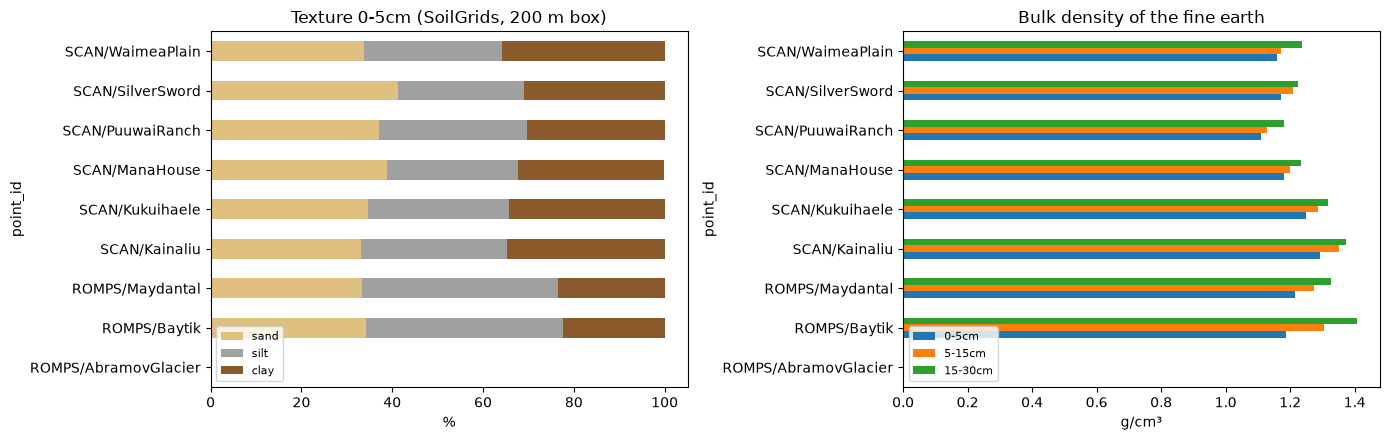

In [12]:
(ANC_DIR / "figures").mkdir(parents=True, exist_ok=True)
d0 = SOIL_DEPTHS[0]
tex = soil_wide[[f"sand_{d0}", f"silt_{d0}", f"clay_{d0}"]]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tex.plot.barh(stacked=True, ax=ax[0], color=["#e0c080", "#a0a0a0", "#8b5a2b"])
ax[0].set(xlabel="%", title=f"Texture {d0} (SoilGrids, {BOX_M:.0f} m box)")
ax[0].legend(["sand", "silt", "clay"], fontsize=8)
soil_wide[[f"bdod_{d}" for d in SOIL_DEPTHS]].plot.barh(ax=ax[1])
ax[1].set(xlabel="g/cm³", title="Bulk density of the fine earth")
ax[1].legend(SOIL_DEPTHS, fontsize=8)
fig.tight_layout()
fig.savefig(ANC_DIR / "figures" / "soilgrids_texture_bulk_density.png", dpi=120)

#### 8.2. NDVI and NDMI time series per station

Filled markers: clear scenes (≥ `MIN_CLEAR_FRACTION` of the box clear); hollow: partly cloudy scenes, mean of the clear pixels only. Vertical lines: BIOMASS acquisitions, one colour per stack.

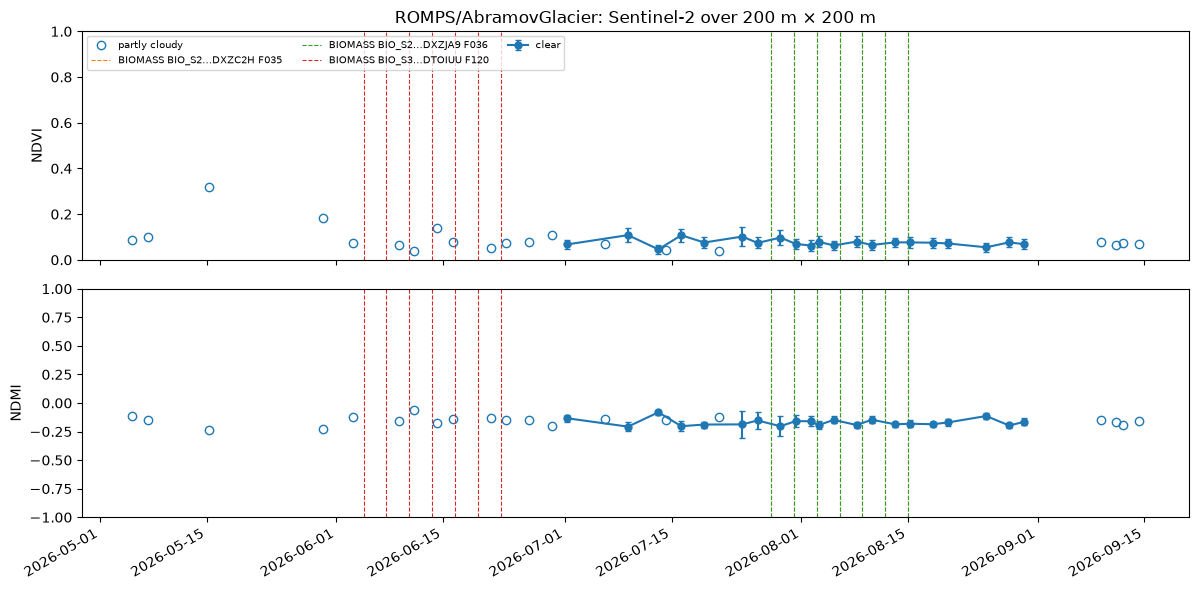

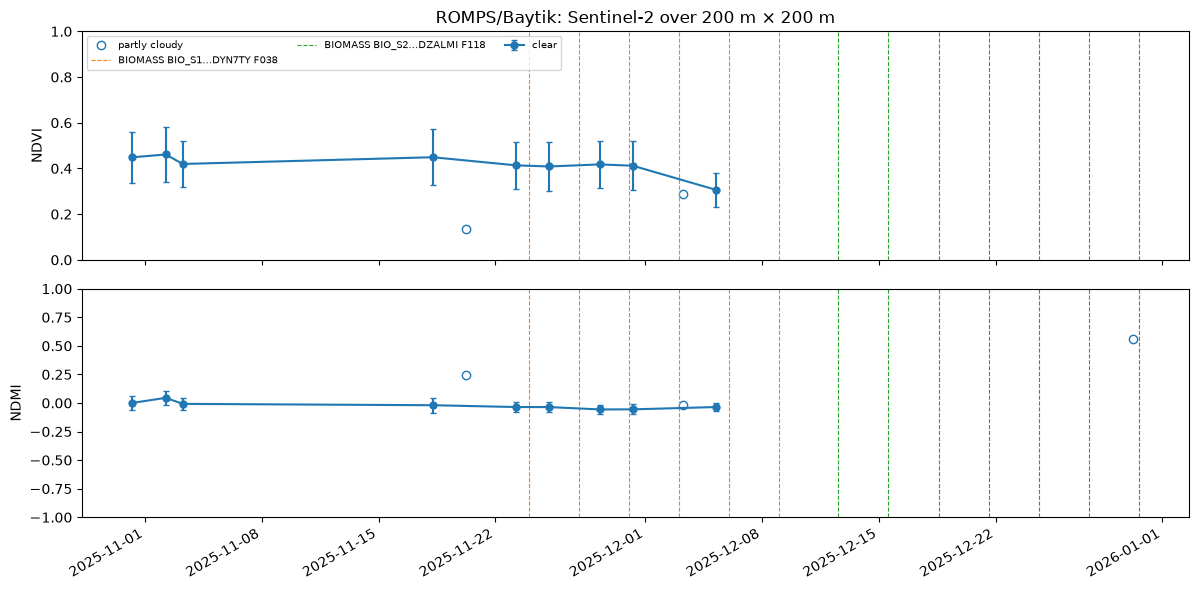

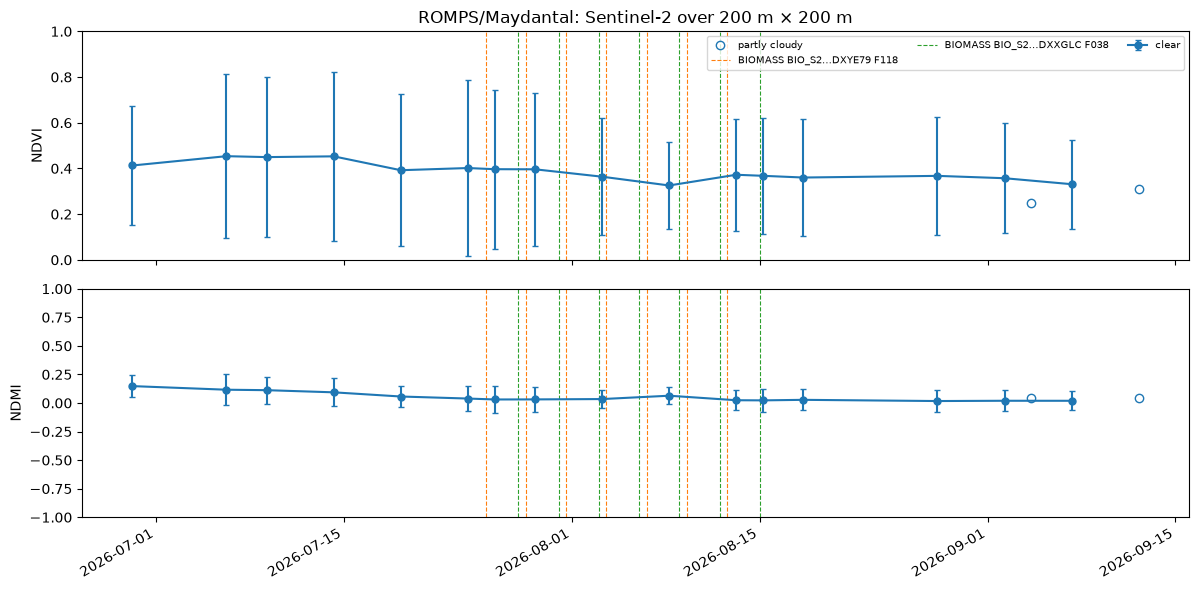

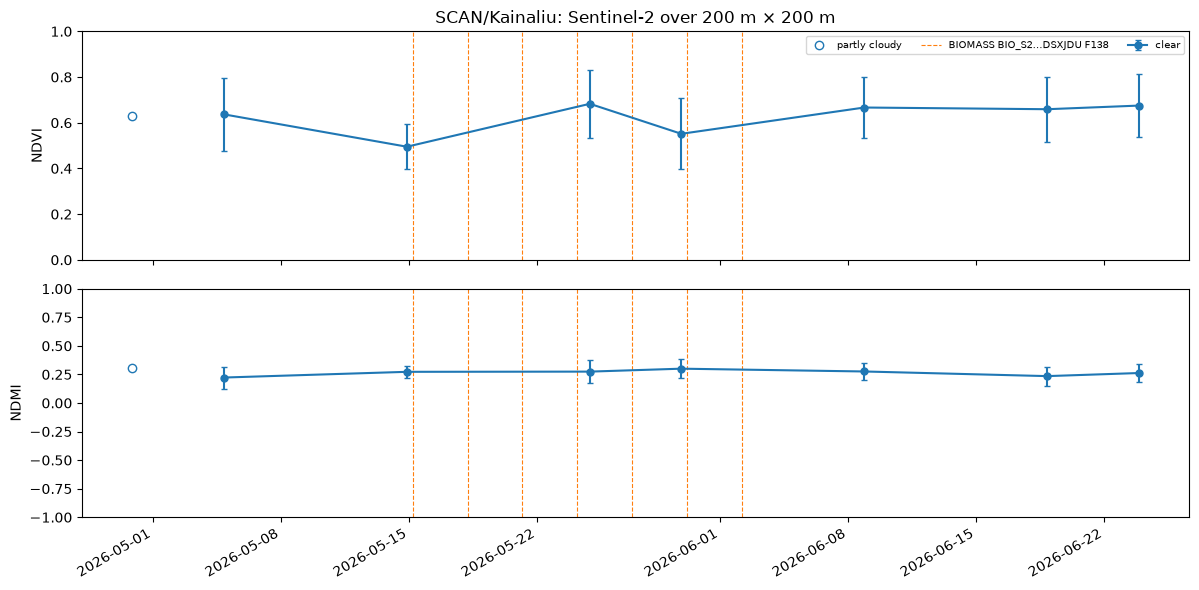

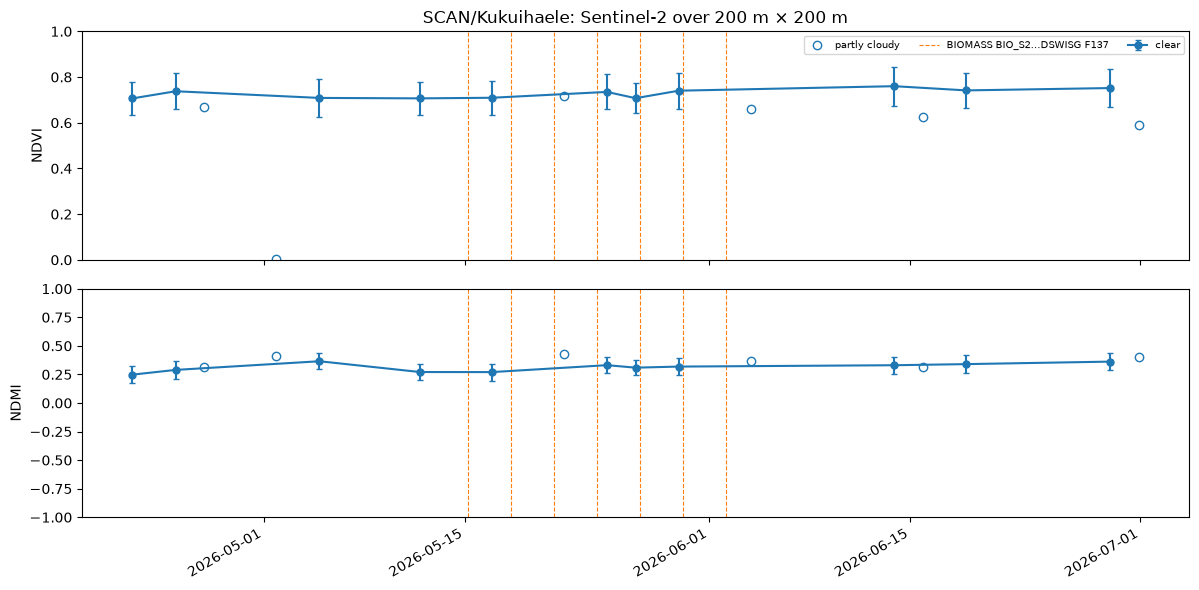

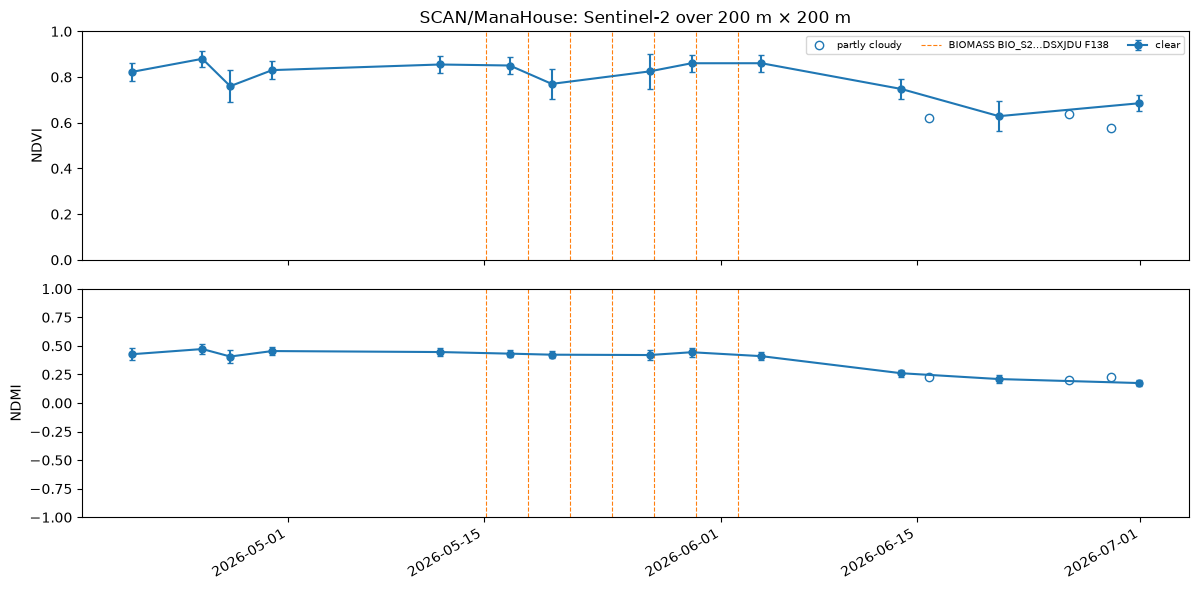

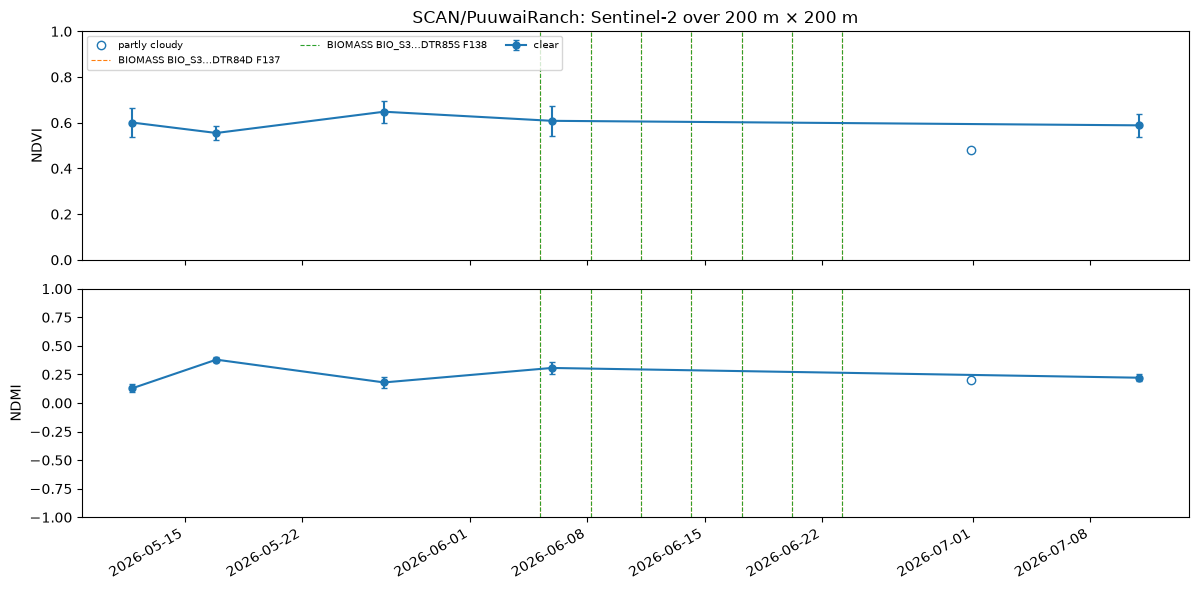

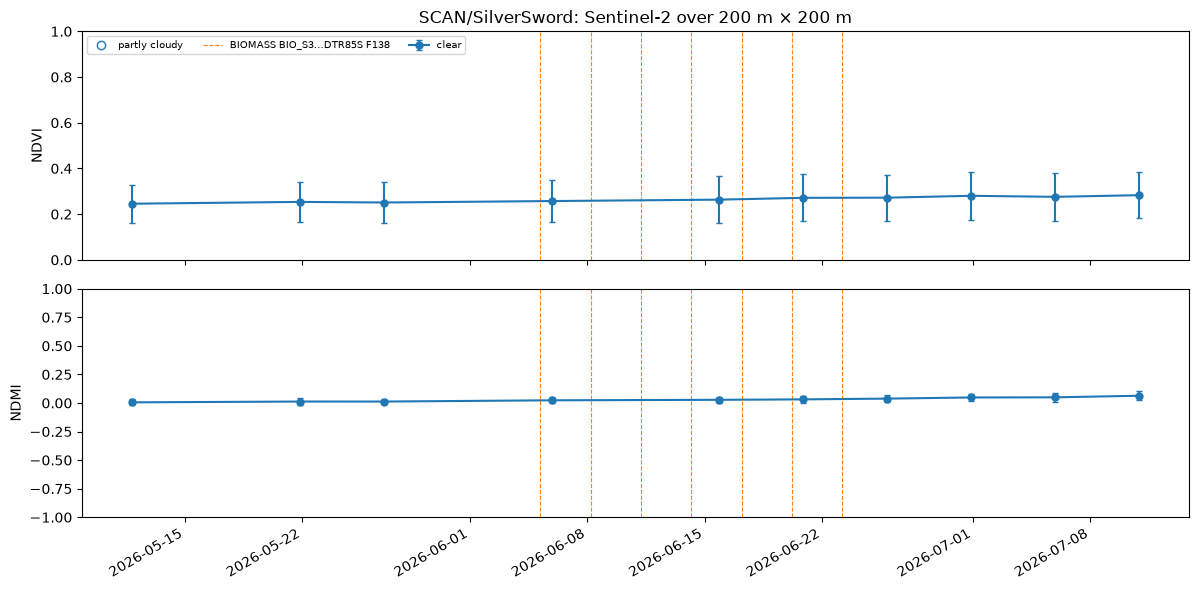

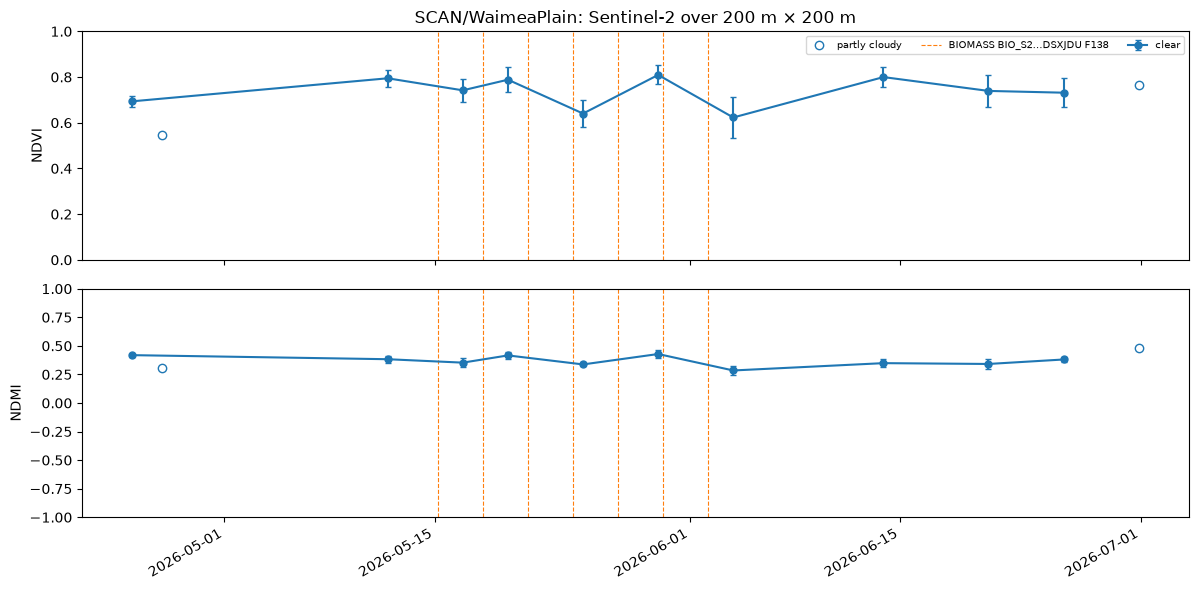

In [13]:
for pid, g in s2.groupby("point_id"):
    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    ep = epochs[epochs["point_id"] == pid]
    stack_colors = dict(zip(ep["stack_id"].unique(), plt.cm.tab10.colors[1:]))   # C0 is the S2 series
    for a, v in zip(ax, ["ndvi", "ndmi"]):
        c = g[g["clear"]]
        a.errorbar(c["datetime"], c[f"{v}_mean"], yerr=c[f"{v}_std"], fmt="o-", ms=5, capsize=2, label="clear")
        p = g[~g["clear"]]
        a.plot(p["datetime"], p[f"{v}_mean"], "o", mfc="none", color="C0", label="partly cloudy")
        for (sid, frame), e in ep.groupby(["stack_id", "frame"]):
            for k, tt in enumerate(e["datetime"]):
                a.axvline(tt, color=stack_colors[sid], lw=0.8, ls="--",
                          label=f"BIOMASS {sid[:6]}…{sid[-6:]} F{frame}" if k == 0 and a is ax[0] else None)
        a.set(ylabel=v.upper(), ylim=YLIM[v])
    ax[0].legend(fontsize=7, ncol=3)
    ax[0].set_title(f"{pid}: Sentinel-2 over {BOX_M:.0f} m × {BOX_M:.0f} m")
    ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(ANC_DIR / "figures" / f"s2_ndvi_ndmi_{pid.replace('/', '_')}.png", dpi=120)
    plt.show()

### 9. Save the results

In [14]:
ANC_DIR.mkdir(parents=True, exist_ok=True)
soil_long.to_csv(ANC_DIR / "soilgrids_long.csv", index=False)
soil_wide.to_csv(ANC_DIR / "soilgrids.csv")
s2.to_csv(ANC_DIR / "s2_scenes.csv", index=False)
biomass_s2.to_csv(ANC_DIR / "s2_at_biomass.csv", index=False)
print(f"Saved to {ANC_DIR.resolve()}")

Saved to C:\NewPersonalDesktop\BIOMASS\pipeline_output\ancillary


Outputs in `ANC_DIR`:
- `soilgrids.csv`: one row per station; mean of each property per depth and over the full depth range (thickness-weighted), in physical units.
- `soilgrids_long.csv`: one row per station × property × depth × statistic (`mean`, `Q0.05`, `Q0.95`), with the unit, the number of SoilGrids pixels overlapped by the box and the valid fraction.
- `s2_scenes.csv`: one row per station × Sentinel-2 date; clear / cloud / snow fractions of the box, NDVI and NDMI (mean, median, std over clear pixels), mean B04/B08/B8A/B11 reflectance.
- `s2_at_biomass.csv`: one row per station × stack × frame × BIOMASS acquisition; nearest clear scene and its time difference, `ndvi/ndmi_nearest` and `ndvi/ndmi_interp`. Join with `acquisitions.csv` on `point_id, stack_id, frame, datetime`.
- `figures/`: texture and bulk density per station, NDVI / NDMI time series per station.